In [1]:
# ==========================================
# Cell 1: Import Libraries
# ==========================================

import os
import sys
import zipfile
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from typing import Union, Tuple, Optional, List

# Ensure project root is in path
for p in [Path.cwd(), Path.cwd().parent]:
    if (p / 'src').is_dir() and str(p) not in sys.path:
        sys.path.insert(0, str(p))

np.random.seed(42)
print('OpenCV Version:', cv2.__version__)
print('NumPy Version :', np.__version__)

OpenCV Version: 5.1.0
NumPy Version : 2.5.5


In [2]:
# ==========================================
# Cell 2: Dataset Path Configuration
# ==========================================

CANDIDATE_DATASET_PATHS = [
    Path("../data/dataset.zip"),
    Path("../data/kvasir-seg.zip"),
    Path("data/dataset.zip"),
    Path("data/kvasir-seg.zip"),
    Path(r"c:\Users\ohmar\OneDrive\Desktop\kvasir-seg.zip"),
    Path.home() / "Desktop" / "kvasir-seg.zip"
]

def get_kvasir_dataset_path() -> Optional[Path]:
    for candidate in CANDIDATE_DATASET_PATHS:
        if candidate.is_file():
            return candidate
    return None

dataset_zip_path = get_kvasir_dataset_path()
print("Dataset Path Found:", dataset_zip_path)

Dataset Path Found: data\dataset.zip


In [3]:
# ==========================================
# Cell 3: Mean Squared Error (MSE)
# ==========================================

def calculate_mse(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    """
    Calculate Mean Squared Error between two images or arrays.
    Formula: MSE = (1 / N) * sum((y_true - y_pred) ** 2)
    """
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    
    if y_true.shape != y_pred.shape:
        raise ValueError(f"Shape mismatch: {y_true.shape} vs {y_pred.shape}")
        
    diff = y_true.astype(np.float64) - y_pred.astype(np.float64)
    return float(np.mean(diff ** 2))

print("calculate_mse function defined successfully.")

calculate_mse function defined successfully.


In [4]:
# ==========================================
# Cell 4: Peak Signal-to-Noise Ratio (PSNR)
# ==========================================

def calculate_psnr(y_true: np.ndarray, y_pred: np.ndarray, max_val: float = 255.0) -> float:
    """
    Calculate Peak Signal-to-Noise Ratio in dB.
    Formula: PSNR = 10 * log10(max_val^2 / MSE)
    """
    mse_value = calculate_mse(y_true, y_pred)
    if mse_value == 0.0:
        return float("inf")
    return float(10.0 * np.log10((max_val ** 2) / mse_value))

print("calculate_psnr function defined successfully.")

calculate_psnr function defined successfully.


In [5]:
# ==========================================
# Cell 5: Intersection over Union (IoU)
# ==========================================

def calculate_iou(y_true: np.ndarray, y_pred: np.ndarray, threshold: float = 0.5) -> float:
    """
    Calculate Intersection over Union (IoU / Jaccard Index) for segmentation masks.
    Formula: IoU = |A ∩ B| / |A ∪ B|
    """
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    
    if y_true.shape != y_pred.shape:
        raise ValueError(f"Shape mismatch: {y_true.shape} vs {y_pred.shape}")
        
    mask_true = y_true if y_true.dtype == bool else (y_true > threshold)
    mask_pred = y_pred if y_pred.dtype == bool else (y_pred > threshold)
    
    intersection = int(np.logical_and(mask_true, mask_pred).sum())
    union = int(np.logical_or(mask_true, mask_pred).sum())
    
    if union == 0:
        return 1.0
        
    return float(intersection / union)

print("calculate_iou function defined successfully.")

calculate_iou function defined successfully.


In [6]:
# ==========================================
# Cell 6: Load Sample from Kvasir-SEG Dataset
# ==========================================

# Ensure candidate paths exist even if run in isolation
if 'CANDIDATE_DATASET_PATHS' not in globals():
    CANDIDATE_DATASET_PATHS = [
        Path("../data/dataset.zip"),
        Path("../data/kvasir-seg.zip"),
        Path("data/dataset.zip"),
        Path("data/kvasir-seg.zip"),
        Path(r"c:\Users\ohmar\OneDrive\Desktop\kvasir-seg.zip"),
        Path.home() / "Desktop" / "kvasir-seg.zip"
    ]

if 'get_kvasir_dataset_path' not in globals():
    def get_kvasir_dataset_path() -> Optional[Path]:
        for candidate in CANDIDATE_DATASET_PATHS:
            if candidate.is_file():
                return candidate
        return None

def load_kvasir_sample(zip_path: Optional[Union[str, Path]] = None, sample_index: int = 0):
    if zip_path is None:
        zip_path = globals().get('dataset_zip_path', None) or get_kvasir_dataset_path()
        
    if zip_path is None or not Path(zip_path).is_file():
        raise FileNotFoundError(f"Dataset archive not found. Searched: {[str(p) for p in CANDIDATE_DATASET_PATHS]}")
        
    zip_path = Path(zip_path)
    with zipfile.ZipFile(zip_path, "r") as archive:
        all_files = archive.namelist()
        image_extensions = (".jpg", ".jpeg", ".png", ".bmp")
        
        image_files = []
        mask_map = {}
        for file in all_files:
            if file.lower().endswith(image_extensions):
                if "/masks/" in file.lower() or file.lower().startswith("masks/"):
                    mask_map[Path(file).stem] = file
                elif "/images/" in file.lower() or file.lower().startswith("images/"):
                    image_files.append(file)
                    
        if not image_files:
            raise ValueError(f"No image files found in {zip_path}")
            
        sample_img_file = image_files[sample_index % len(image_files)]
        sample_name = Path(sample_img_file).stem
        sample_mask_file = mask_map[sample_name]
        
        # Read image
        img_bytes = archive.read(sample_img_file)
        img = cv2.imdecode(np.frombuffer(img_bytes, dtype=np.uint8), cv2.IMREAD_COLOR)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        
        # Read mask
        mask_bytes = archive.read(sample_mask_file)
        mask = cv2.imdecode(np.frombuffer(mask_bytes, dtype=np.uint8), cv2.IMREAD_GRAYSCALE)
        mask_binary = (mask > 127).astype(np.uint8)
        
        return img, mask_binary, sample_name

# Automatically resolves dataset path without relying on previous cells
image, mask, sample_name = load_kvasir_sample(sample_index=0)
print(f"Loaded Sample: {sample_name}.jpg")
print(f"Image Shape  : {image.shape}")
print(f"Mask Shape   : {mask.shape} (Polyp pixel count: {mask.sum()})")


Loaded Sample: ck2bxiswtxuw80838qkisqjwz.jpg
Image Shape  : (520, 621, 3)
Mask Shape   : (520, 621) (Polyp pixel count: 142856)


In [7]:
# ==========================================
# Cell 7: Noise Degradation Functions (from data.py)
# ==========================================

def add_gaussian_noise(img, seed=42):
    rng = np.random.default_rng(seed)
    noise = rng.normal(0, 25, img.shape)
    return np.clip(img.astype(np.float32) + noise, 0, 255).astype(np.uint8)

def add_salt_pepper_noise(img, seed=42, amount=0.05):
    rng = np.random.default_rng(seed)
    noisy = img.copy()
    total_pixels = img.shape[0] * img.shape[1]
    num_pixels = int(total_pixels * amount)
    indices = rng.choice(total_pixels, num_pixels, replace=False)
    rows = indices // img.shape[1]
    cols = indices % img.shape[1]
    half = num_pixels // 2
    noisy[rows[:half], cols[:half]] = 255
    noisy[rows[half:], cols[half:]] = 0
    return noisy

def add_speckle_noise(img, seed=42):
    rng = np.random.default_rng(seed)
    noise = rng.normal(0, 0.1, img.shape)
    return np.clip(img.astype(np.float32) * (1 + noise), 0, 255).astype(np.uint8)

def add_poisson_noise(img, seed=42):
    rng = np.random.default_rng(seed)
    return np.clip(rng.poisson(img.astype(np.float32)), 0, 255).astype(np.uint8)

print("Noise degradation functions initialized.")

Noise degradation functions initialized.


In [8]:
# ==========================================
# Cell 8: Hand-Crafted Verification Tests (from src/metrics.py)
# ==========================================

def run_hand_crafted_tests():
    print("=" * 60)
    print("Running Hand-Crafted Verification Tests on Small Arrays")
    print("=" * 60)
    
    # 1. MSE Test on 2x2 Array (Expected = 7.25)
    a_true = np.array([[10, 20], [30, 40]], dtype=np.uint8)
    a_pred = np.array([[12, 20], [25, 40]], dtype=np.uint8)
    computed_mse = calculate_mse(a_true, a_pred)
    expected_mse = 7.25
    print(f"\n[Test 1] MSE Check:")
    print(f"  Expected MSE : {expected_mse}")
    print(f"  Computed MSE : {computed_mse}")
    assert np.isclose(computed_mse, expected_mse)
    print("  -> Result: PASSED")
    
    # 2. PSNR Test (Expected ≈ 39.52742 dB)
    computed_psnr = calculate_psnr(a_true, a_pred, max_val=255.0)
    expected_psnr = 10.0 * np.log10((255.0 ** 2) / 7.25)
    print(f"\n[Test 2] PSNR Check:")
    print(f"  Expected PSNR: {expected_psnr:.5f} dB")
    print(f"  Computed PSNR: {computed_psnr:.5f} dB")
    assert np.isclose(computed_psnr, expected_psnr)
    print("  -> Result: PASSED")
    
    # 3. IoU Test on 3x3 Array (Intersection=2, Union=4, Expected = 0.50)
    m_true = np.array([[1, 1, 0], [0, 1, 0], [0, 0, 0]], dtype=np.uint8)
    m_pred = np.array([[1, 0, 0], [0, 1, 1], [0, 0, 0]], dtype=np.uint8)
    computed_iou = calculate_iou(m_true, m_pred)
    expected_iou = 0.50
    print(f"\n[Test 3] IoU Check:")
    print(f"  Intersection : 2 | Union : 4")
    print(f"  Expected IoU : {expected_iou}")
    print(f"  Computed IoU : {computed_iou}")
    assert np.isclose(computed_iou, expected_iou)
    print("  -> Result: PASSED")
    
    # 4. Edge Cases
    assert calculate_psnr(a_true, a_true) == float('inf')
    assert calculate_iou(np.zeros((3, 3)), np.zeros((3, 3))) == 1.0
    assert calculate_iou(np.array([[1, 0]]), np.array([[0, 1]])) == 0.0
    print("\n[Test 4] Edge Cases: ALL PASSED!")

run_hand_crafted_tests()

Running Hand-Crafted Verification Tests on Small Arrays

[Test 1] MSE Check:
  Expected MSE : 7.25
  Computed MSE : 7.25
  -> Result: PASSED

[Test 2] PSNR Check:
  Expected PSNR: 39.52742 dB
  Computed PSNR: 39.52742 dB
  -> Result: PASSED

[Test 3] IoU Check:
  Intersection : 2 | Union : 4
  Expected IoU : 0.5
  Computed IoU : 0.5
  -> Result: PASSED

[Test 4] Edge Cases: ALL PASSED!


In [9]:
# ==========================================
# Cell 9: Kvasir-SEG Dataset Evaluation (from src/metrics.py)
# ==========================================

def run_kvasir_dataset_evaluation():
    print("=" * 60)
    print("Running Metrics Validation on Dataset (ck2bxiswtxuw80838qkisqjwz)")
    print("=" * 60)
    
    # Apply degradations matching 01_image_analysis.ipynb
    gaussian_noisy = add_gaussian_noise(image)
    sp_noisy = add_salt_pepper_noise(image)
    speckle_noisy = add_speckle_noise(image)
    poisson_noisy = add_poisson_noise(image)
    
    print("\n[Controlled Degradation Quality Evaluation - MSE & PSNR]")
    degradations = [
        ("Gaussian Noise", gaussian_noisy),
        ("Salt & Pepper", sp_noisy),
        ("Speckle Noise", speckle_noisy),
        ("Poisson Noise", poisson_noisy),
    ]
    
    for name, noisy in degradations:
        mse_val = calculate_mse(image, noisy)
        psnr_val = calculate_psnr(image, noisy)
        print(f"  {name:<15} -> MSE: {mse_val:8.2f} | PSNR: {psnr_val:5.2f} dB")
        
    # Apply restoration filters matching data.py
    mean_restored = cv2.blur(gaussian_noisy, (5, 5))
    gaussian_restored = cv2.GaussianBlur(gaussian_noisy, (5, 5), 1.5)
    median_restored = cv2.medianBlur(gaussian_noisy, 5)
    
    print("\n[Restoration Quality Evaluation (Gaussian Input) - MSE & PSNR]")
    restorations = [
        ("Noisy Gaussian", gaussian_noisy),
        ("Mean Filter (5x5)", mean_restored),
        ("Gaussian Filter", gaussian_restored),
        ("Median Filter (5x5)", median_restored),
    ]
    
    for name, restored in restorations:
        mse_val = calculate_mse(image, restored)
        psnr_val = calculate_psnr(image, restored)
        print(f"  {name:<20} -> MSE: {mse_val:8.2f} | PSNR: {psnr_val:5.2f} dB")
        
    # Evaluate segmentation mask IoU
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))
    pred_dilated = cv2.dilate(mask, kernel, iterations=1)
    pred_eroded = cv2.erode(mask, kernel, iterations=1)
    
    iou_dilated = calculate_iou(mask, pred_dilated)
    iou_eroded = calculate_iou(mask, pred_eroded)
    
    print("\n[Segmentation Mask Overlap Evaluation - IoU]")
    print(f"  Ground Truth Area : {mask.sum()} pixels")
    print(f"  Dilated Mask IoU  : {iou_dilated:.4f} ({iou_dilated * 100:.2f}%)")
    print(f"  Eroded Mask IoU   : {iou_eroded:.4f} ({iou_eroded * 100:.2f}%)")
    print("=" * 60)

run_kvasir_dataset_evaluation()

Running Metrics Validation on Dataset (ck2bxiswtxuw80838qkisqjwz)

[Controlled Degradation Quality Evaluation - MSE & PSNR]
  Gaussian Noise  -> MSE:   523.62 | PSNR: 20.94 dB
  Salt & Pepper   -> MSE:  1151.22 | PSNR: 17.52 dB
  Speckle Noise   -> MSE:   129.03 | PSNR: 27.02 dB
  Poisson Noise   -> MSE:    88.06 | PSNR: 28.68 dB

[Restoration Quality Evaluation (Gaussian Input) - MSE & PSNR]
  Noisy Gaussian       -> MSE:   523.62 | PSNR: 20.94 dB
  Mean Filter (5x5)    -> MSE:    66.43 | PSNR: 29.91 dB
  Gaussian Filter      -> MSE:    63.35 | PSNR: 30.11 dB
  Median Filter (5x5)  -> MSE:    53.18 | PSNR: 30.87 dB

[Segmentation Mask Overlap Evaluation - IoU]
  Ground Truth Area : 142856 pixels
  Dilated Mask IoU  : 0.9099 (90.99%)
  Eroded Mask IoU   : 0.8911 (89.11%)


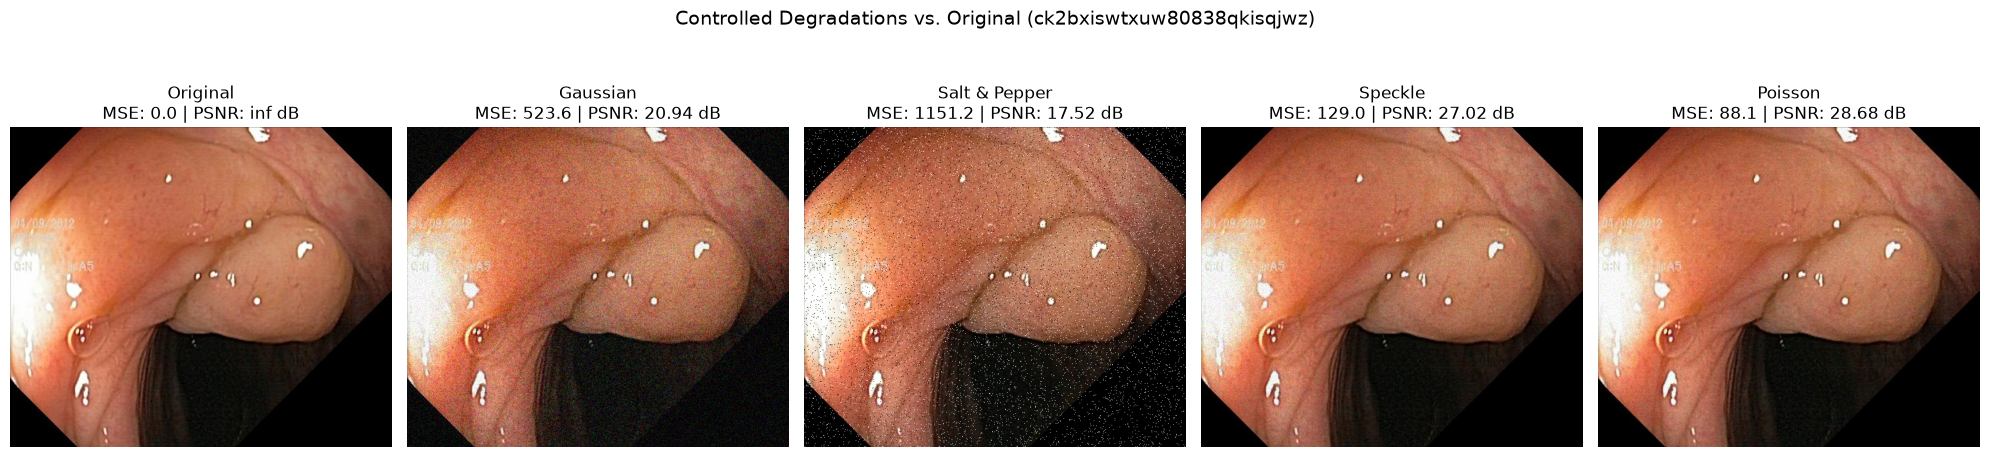

In [10]:
# ==========================================
# Cell 10: Visual Comparison of Degradations with MSE & PSNR
# ==========================================

gaussian_noisy = add_gaussian_noise(image)
salt_pepper_noisy = add_salt_pepper_noise(image)
speckle_noisy = add_speckle_noise(image)
poisson_noisy = add_poisson_noise(image)

images = [image, gaussian_noisy, salt_pepper_noisy, speckle_noisy, poisson_noisy]
titles = ["Original", "Gaussian", "Salt & Pepper", "Speckle", "Poisson"]

plt.figure(figsize=(20, 5))
for i in range(len(images)):
    mse_v = calculate_mse(image, images[i])
    psnr_v = calculate_psnr(image, images[i])
    plt.subplot(1, 5, i + 1)
    plt.imshow(images[i])
    plt.title(f"{titles[i]}\nMSE: {mse_v:.1f} | PSNR: {psnr_v:.2f} dB")
    plt.axis("off")

plt.suptitle("Controlled Degradations vs. Original (ck2bxiswtxuw80838qkisqjwz)", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

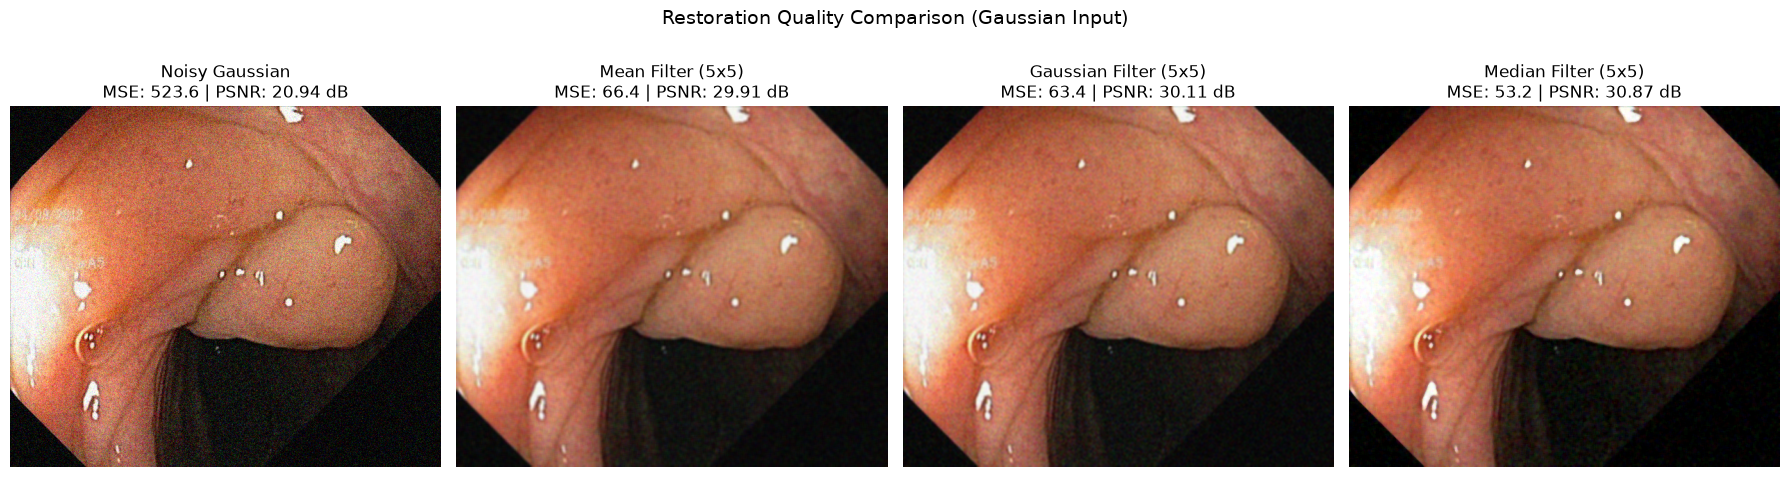

In [11]:
# ==========================================
# Cell 11: Visual Comparison of Restoration Filters
# ==========================================

mean_restored = cv2.blur(gaussian_noisy, (5, 5))
gaussian_restored = cv2.GaussianBlur(gaussian_noisy, (5, 5), 1.5)
median_restored = cv2.medianBlur(gaussian_noisy, 5)

restorations = [
    ("Noisy Gaussian", gaussian_noisy),
    ("Mean Filter (5x5)", mean_restored),
    ("Gaussian Filter (5x5)", gaussian_restored),
    ("Median Filter (5x5)", median_restored)
]

plt.figure(figsize=(18, 5))
for i, (name, img_r) in enumerate(restorations):
    mse_v = calculate_mse(image, img_r)
    psnr_v = calculate_psnr(image, img_r)
    plt.subplot(1, 4, i + 1)
    plt.imshow(img_r)
    plt.title(f"{name}\nMSE: {mse_v:.1f} | PSNR: {psnr_v:.2f} dB")
    plt.axis("off")

plt.suptitle("Restoration Quality Comparison (Gaussian Input)", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

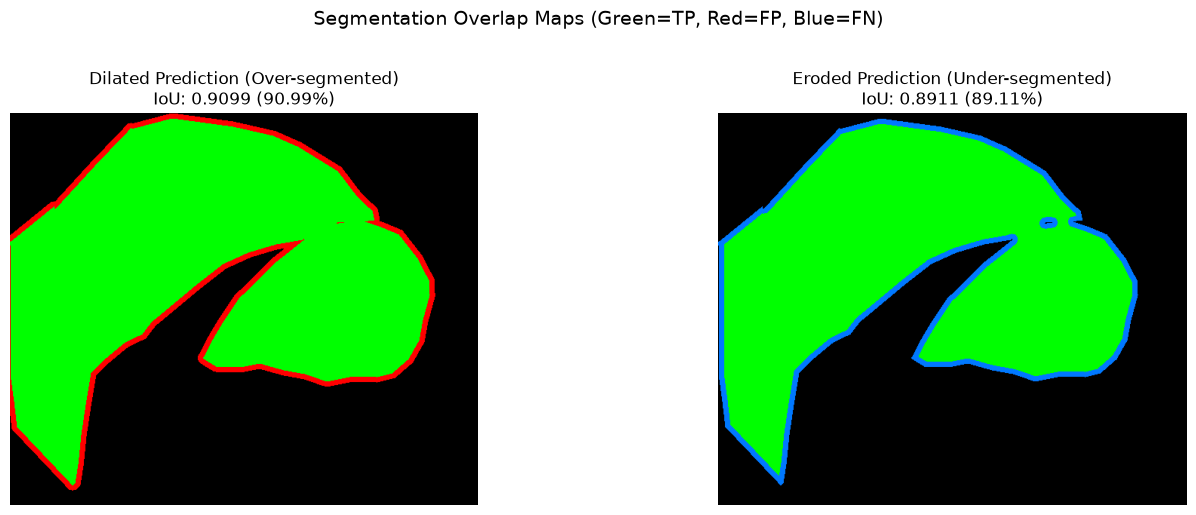

In [12]:
# ==========================================
# Cell 12: Visual Comparison of Segmentation IoU Overlap
# ==========================================

kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))
pred_dilated = cv2.dilate(mask, kernel, iterations=1)
pred_eroded = cv2.erode(mask, kernel, iterations=1)

preds = [
    ("Dilated Prediction (Over-segmented)", pred_dilated),
    ("Eroded Prediction (Under-segmented)", pred_eroded)
]

plt.figure(figsize=(15, 5))
for i, (name, pmask) in enumerate(preds):
    iou_v = calculate_iou(mask, pmask)
    
    # Construct color overlap map: Green = TP (Overlap), Red = FP, Blue = FN
    overlap = np.zeros((*mask.shape, 3), dtype=np.uint8)
    overlap[(mask == 1) & (pmask == 1)] = [0, 255, 0]   # TP (Intersection)
    overlap[(mask == 0) & (pmask == 1)] = [255, 0, 0]   # FP
    overlap[(mask == 1) & (pmask == 0)] = [0, 120, 255] # FN
    
    plt.subplot(1, 2, i + 1)
    plt.imshow(overlap)
    plt.title(f"{name}\nIoU: {iou_v:.4f} ({iou_v * 100:.2f}%)")
    plt.axis("off")

plt.suptitle("Segmentation Overlap Maps (Green=TP, Red=FP, Blue=FN)", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

### 🚀 Integration with Project Pipeline

```python
from src.metrics import calculate_mse, calculate_psnr, calculate_iou

# Evaluate restoration
mse = calculate_mse(clean_image, restored_image)
psnr = calculate_psnr(clean_image, restored_image)

# Evaluate segmentation
iou = calculate_iou(ground_truth_mask, predicted_mask)
```